In [1]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Rescaling
import matplotlib.pyplot as plt
import numpy as np

In [8]:
train_dir = r'C:\Users\Admin\Downloads\brain tumour\Training'
test_dir = r'C:\Users\Admin\Downloads\brain tumour\Testing'

In [9]:
img_height,img_width = 150,150
batch_size =32

In [10]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size =(img_height,img_width),
    batch_size=batch_size
)

Found 2870 files belonging to 4 classes.


In [11]:
test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size =(img_height,img_width),
    batch_size=batch_size
)

Found 394 files belonging to 4 classes.


In [13]:
class_names = train_dataset.class_names
num_classes = len(class_names)
print(f"Detected Classes: {class_names}")

Detected Classes: ['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']


In [16]:
model = Sequential([
    Rescaling(1./255,input_shape=(img_height,img_width,3)),
    Conv2D(32,(3,3),activation='relu'),
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(64,(3,3),activation='relu'),
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(128,activation='relu'),
    Dense(num_classes,activation='softmax')
])

In [20]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [21]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 82944)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    10,616,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,636,868 (40.58 MB)

 Trainable params: 10,636,868 (40.58 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
history = model.fit(train_dataset,epochs=5,validation_data = test_dataset)

Epoch 1/5
90/90 ━━━━━━━━━━━━━━━━━━━━ 84s 872ms/step - accuracy: 0.5993 - loss: 0.9953 - val_accuracy: 0.4340 - val_loss: 1.6787
Epoch 2/5
90/90 ━━━━━━━━━━━━━━━━━━━━ 69s 733ms/step - accuracy: 0.8202 - loss: 0.4460 - val_accuracy: 0.6294 - val_loss: 1.7277
Epoch 3/5
90/90 ━━━━━━━━━━━━━━━━━━━━ 82s 728ms/step - accuracy: 0.9111 - loss: 0.2367 - val_accuracy: 0.6853 - val_loss: 1.5850
Epoch 4/5
90/90 ━━━━━━━━━━━━━━━━━━━━ 67s 749ms/step - accuracy: 0.9561 - loss: 0.1305 - val_accuracy: 0.6827 - val_loss: 2.2700
Epoch 5/5
90/90 ━━━━━━━━━━━━━━━━━━━━ 84s 771ms/step - accuracy: 0.9854 - loss: 0.0558 - val_accuracy: 0.7259 - val_loss: 2.3968


In [23]:
plt.figure(figsize=(12,4))

<Figure size 1200x400 with 0 Axes>

<Figure size 1200x400 with 0 Axes>

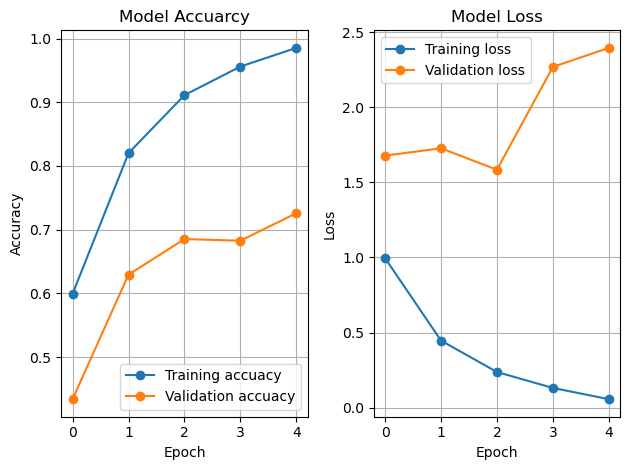

In [24]:
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'],label='Training accuacy',marker='o')
plt.plot(history.history['val_accuracy'],label='Validation accuacy',marker='o')
plt.title('Model Accuarcy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True)
plt.subplot(1,2,2)
plt.plot(history.history['loss'],label='Training loss',marker='o')
plt.plot(history.history['val_loss'],label='Validation loss',marker='o')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [25]:
for images,labels in test_dataset.take(1):
    img = images[0]
    actual_lab = int(labels[0].numpy())
    break
prediction_prob = model.predict(tf.expand_dims(img,axis=0))
predicted_label = np.argmax(prediction_prob)

print(f"Predicted Class:{class_names[predicted_label]}")
print(f"Actual Class:{class_names[actual_lab]}")



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step
Predicted Class:glioma_tumor
Actual Class:glioma_tumor


In [26]:
plt.figure(figsize=(4,4))

<Figure size 400x400 with 0 Axes>

<Figure size 400x400 with 0 Axes>

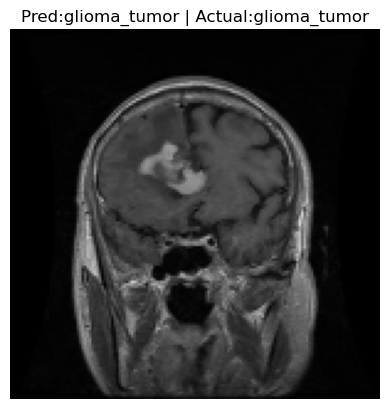

In [32]:
plt.imshow(img.numpy().astype('uint8'))
plt.title(f"Pred:{class_names[predicted_label]} | Actual:{class_names[actual_lab]}")
plt.axis('off')
plt.show()